In [1]:
import os
import json
from pathlib import Path

def folder_size(p: Path) -> int:
    if not p.exists():
        return 0
    total = 0
    for dirpath, _, filenames in os.walk(p, followlinks=False):
        for name in filenames:
            fp = Path(dirpath) / name
            try:
                total += fp.stat().st_size
            except (FileNotFoundError, PermissionError):
                pass  # broken symlinks, unreadable files
    return total

def has_ply(p: Path) -> bool:
    return any(p.rglob("*.ply"))

def gaussian_count(p: Path) -> int:
    """Number of Gaussians in a scene, read from gaussian_splats/meta.json.

    Returns 0 if the scene has no gaussian_splats/meta.json.
    """
    meta = p / "gaussian_splats" / "meta.json"
    if not meta.exists():
        return 0
    with open(meta) as f:
        return json.load(f)["means"]["shape"][0]

In [2]:
import pandas as pd

root = Path("/mnt/hdd/lkuech/repos/radiance-field-project/data/uco3d_data_raw")
rows = []
for scene_dir in root.glob("*/*/*"):
    if not scene_dir.is_dir() or not has_ply(scene_dir):
        continue

    rel = scene_dir.relative_to(root).parts

    rows.append({
        "super_category": rel[0],
        "category":       rel[1],
        "scene_id":       rel[2],
        "scene_size_mb":  folder_size(scene_dir) / 1e6,
        "n_gaussians":    gaussian_count(scene_dir),
    })

df = pd.DataFrame(rows)

df.describe()

,scene_size_mb,n_gaussians
count,52.000000,5.200000e+01
mean,184.557488,4.199108e+05
std,65.804630,6.041676e+05
min,79.650661,1.866240e+05
25%,138.612018,2.500000e+05
50%,179.393954,2.500000e+05
75%,217.084672,2.500000e+05
max,373.843463,3.697929e+06


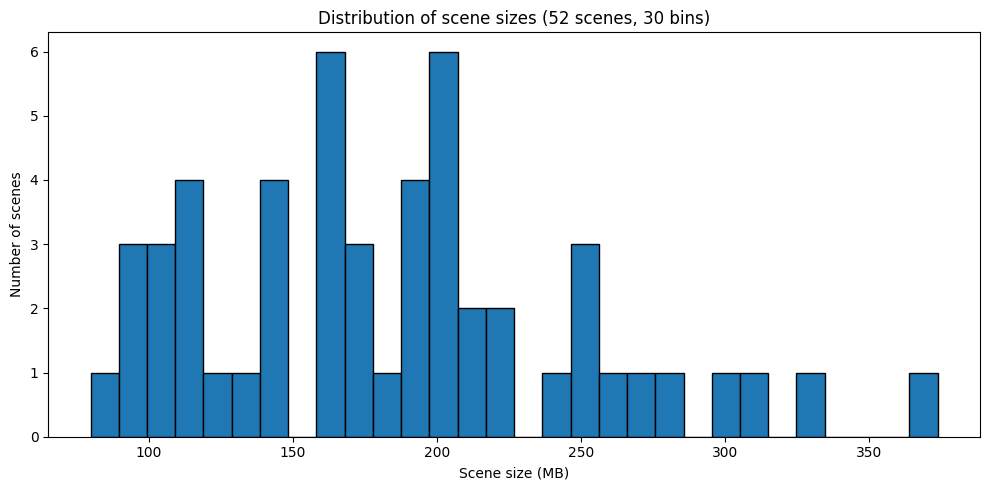

,bin_start_mb,bin_end_mb,n_scenes
0,79.650661,89.457088,1
1,89.457088,99.263514,3
2,99.263514,109.069941,3
3,109.069941,118.876368,4
4,118.876368,128.682795,1
5,128.682795,138.489221,1
6,138.489221,148.295648,4
7,148.295648,158.102075,0
8,158.102075,167.908502,6
9,167.908502,177.714928,3


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Bin the scenes by size and show how many fall into each bin
n_bins = 30
counts, bin_edges = np.histogram(df["scene_size_mb"], bins=n_bins)

fig, axis = plt.subplots(figsize=(10, 5))
axis.bar(
    bin_edges[:-1],
    counts,
    width=np.diff(bin_edges),
    align="edge",
    edgecolor="black",
)
axis.set_xlabel("Scene size (MB)")
axis.set_ylabel("Number of scenes")
axis.set_title(f"Distribution of scene sizes ({len(df)} scenes, {n_bins} bins)")
fig.tight_layout()
plt.show()

# Tabular view of the bins
bins_df = pd.DataFrame({
    "bin_start_mb": bin_edges[:-1],
    "bin_end_mb":   bin_edges[1:],
    "n_scenes":     counts,
})
bins_df

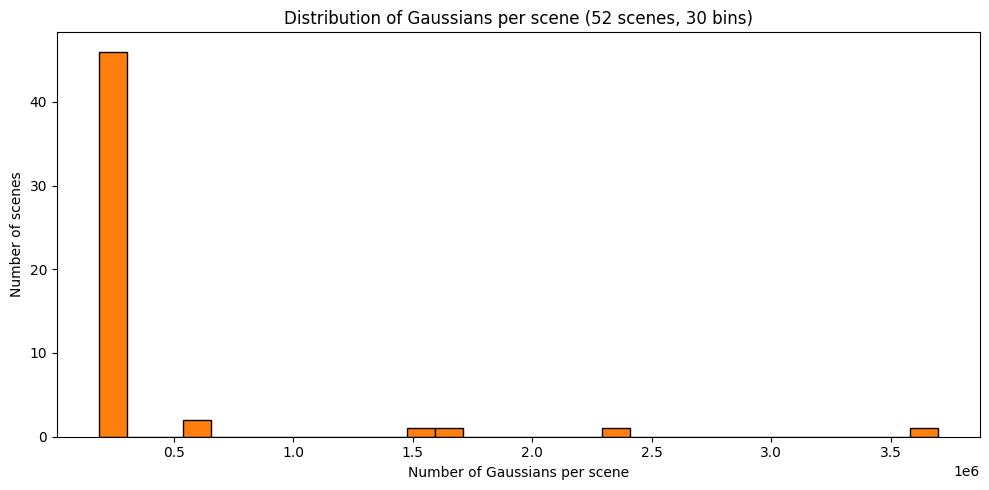

,bin_start,bin_end,n_scenes
0,186624,303667,46
1,303667,420711,0
2,420711,537754,0
3,537754,654798,2
4,654798,771841,0
5,771841,888885,0
6,888885,1005928,0
7,1005928,1122972,0
8,1122972,1240015,0
9,1240015,1357059,0


In [4]:
# Distribution of the number of Gaussians per scene
gauss = df.loc[df["n_gaussians"] > 0, "n_gaussians"]

n_bins = 30
counts, bin_edges = np.histogram(gauss, bins=n_bins)

fig, axis = plt.subplots(figsize=(10, 5))
axis.bar(
    bin_edges[:-1],
    counts,
    width=np.diff(bin_edges),
    align="edge",
    edgecolor="black",
    color="tab:orange",
)
axis.set_xlabel("Number of Gaussians per scene")
axis.set_ylabel("Number of scenes")
axis.set_title(f"Distribution of Gaussians per scene ({len(gauss)} scenes, {n_bins} bins)")
fig.tight_layout()
plt.show()

# Tabular view of the bins
gauss_bins_df = pd.DataFrame({
    "bin_start": bin_edges[:-1].astype(int),
    "bin_end":   bin_edges[1:].astype(int),
    "n_scenes":  counts,
})
gauss_bins_df